# AE801 Scientific Computing Lab I
## Leapfrog Particle Pusher for the Plasma-Oscillation IVP — Matrix / Amplification-Factor Approach

**Name:** SOUMEN SARDAR &nbsp;&nbsp; **Roll No.:** SC26M017

**Problem** (normalized units, $\omega_p = 1$):

$$
\dot x = v,\qquad \dot v = -\omega_p^2 x,\qquad x(0)=0.5,\ v(0)=0,\qquad 0\le t\le 20,
$$

with exact solution $x(t)=0.5\cos t$, $v(t)=-0.5\sin t$.

**Approach used in this report.** Because the force is linear in $x$, one leapfrog step is a *linear map* on the state vector $\mathbf{u}^n = (x^n,\ v^{n-1/2})^T$:

$$
\mathbf{u}^{n+1} = \mathbf{M}(h)\,\mathbf{u}^n .
$$

The pusher itself is written generally, as a class that takes any force function, so it works for many particles as in a PIC code. The matrix $\mathbf{M}$ is then used as an independent check of the code (Task 3), to derive the central-difference form via Cayley–Hamilton (Task 5), and to obtain the stability limit from its eigenvalues (Task 6). Convergence orders (Task 4) are found by a least-squares fit of $\log e$ against $\log h$, and the algebra is verified symbolically with SymPy.

In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

OMEGA_P, X0, V0, T_END = 1.0, 0.5, 0.0, 20.0
x_exact = lambda t: 0.5*np.cos(OMEGA_P*t)
v_exact = lambda t: -0.5*np.sin(OMEGA_P*t)

## Task 1 — A reusable, vectorized leapfrog pusher

The pusher is a small class holding particle arrays `x` (at $t_n$) and `v` (at $t_{n-1/2}$) and a user-supplied acceleration function $a(x,t) = \frac{q}{m}E(x,t)$. A step is

$$
v \leftarrow v + h\,a(x,t_n)\quad(\text{kick}),\qquad x \leftarrow x + h\,v\quad(\text{drift}).
$$

The arrays are updated **in place**, with no Python loop over particles, so the same object pushes one particle or $10^6$, which is how a PIC particle pusher is organised.

In [ ]:
class LeapfrogPusher:
    # Leapfrog pusher for N particles.
    #   x : positions at t_n            (ndarray, shape (N,))
    #   v : velocities at t_{n-1/2}     (ndarray, shape (N,))
    #   accel(x, t) : acceleration (q/m) E evaluated at the particle positions
    def __init__(self, x, v, accel, h, t0=0.0):
        self.x = np.atleast_1d(np.asarray(x, dtype=float)).copy()
        self.v = np.atleast_1d(np.asarray(v, dtype=float)).copy()
        self.accel, self.h, self.t = accel, h, t0

    def step(self):
        self.v += self.h * self.accel(self.x, self.t)   # kick : v^{n-1/2} -> v^{n+1/2}
        self.x += self.h * self.v                       # drift: x^n       -> x^{n+1}
        self.t += self.h

    def run(self, nsteps):
        # Advance nsteps; return histories X[n] = x^n (n=0..N) and V[n] = v^{n+1/2} (n=0..N-1)
        X = np.empty((nsteps + 1, self.x.size)); V = np.empty((nsteps, self.x.size))
        X[0] = self.x
        for n in range(nsteps):
            self.step()
            X[n + 1], V[n] = self.x, self.v
        return X, V

def plasma_accel(x, t, omega_p=OMEGA_P):
    return -omega_p**2 * x

**Many-particle test.** $10^5$ particles with random initial displacements are pushed in one object. Every particle should follow $x_i(t)=x_{0,i}\cos t$, so the ratio $x_i(20)/x_{0,i}$ should be the same for all of them and close to $\cos 20$.

In [ ]:
rng = np.random.default_rng(1)
h = 0.1
x0p = rng.uniform(-1, 1, 100_000)
p = LeapfrogPusher(x0p, -0.5*h*plasma_accel(x0p, 0), plasma_accel, h)   # staggered start, Task 2
for _ in range(int(round(T_END/h))):
    p.step()
ratio = p.x / x0p
print(f"particles pushed      : {x0p.size}")
print(f"x(20)/x0  mean = {ratio.mean():.6f},  spread (std) = {ratio.std():.1e}")
print(f"cos(20)              = {np.cos(20):.6f}")

particles pushed      : 100000
x(20)/x0  mean = 0.400452,  spread (std) = 4.0e-16
cos(20)              = 0.408082


## Task 2 — Half-step initialization

We need $v^{-1/2}\approx v(-h/2)$. Expanding in a Taylor series about $t=0$,

$$
v(-\tfrac h2) = v^0 - \tfrac h2\,\dot v(0) + \tfrac{h^2}{8}\ddot v(0) - \cdots
            = v^0 - \tfrac h2\,a(x^0) + O(h^2).
$$

Keeping the first two terms gives the required initializer $v^{-1/2} = v^0 - \tfrac h2 a(x^0)$. SymPy confirms that the leftover error is $O(h^2)$ in general. For this problem it is even smaller, $O(h^3)$, because $\ddot v(0) = -\omega_p^2 v^0 = 0$.

In [ ]:
def init_half_step(x0, v0, h, accel=plasma_accel):
    return v0 - 0.5*h*accel(np.asarray(x0, float), 0.0)

hs_, t_ = sp.symbols("h t", positive=True)
w = sp.Symbol("omega_p", positive=True)
A, B = sp.symbols("A B")
x_sym = A*sp.cos(w*t_) + B*sp.sin(w*t_)        # general solution
v_sym = sp.diff(x_sym, t_)
x0s, v0s = x_sym.subs(t_, 0), v_sym.subs(t_, 0)
err = sp.series(v_sym.subs(t_, -hs_/2) - (v0s + hs_/2*w**2*x0s), hs_, 0, 4).removeO()
print("v(-h/2) - v^{-1/2} =", sp.simplify(err))
print("for x(0)=0.5, v(0)=0 :", sp.simplify(err.subs({A: sp.Rational(1, 2), B: 0})))

v(-h/2) - v^{-1/2} = h**2*omega_p**3*(-A*h*omega_p - 6*B)/48
for x(0)=0.5, v(0)=0 : -h**3*omega_p**4/96


## Task 3 — Checking the implementation ($h=0.1$)

Two independent checks are used:

1. **Against the exact solution**, plotting $x^n$ at $t_n=nh$ and $v^{n+1/2}$ at $t_{n+1/2}=(n+\tfrac12)h$.
2. **Against the matrix form.** Substituting the kick into the drift gives

$$
\begin{pmatrix} x^{n+1}\\ v^{n+1/2}\end{pmatrix}
=\underbrace{\begin{pmatrix} 1-\omega_p^2h^2 & h\\ -\omega_p^2 h & 1\end{pmatrix}}_{\mathbf M}
\begin{pmatrix} x^{n}\\ v^{n-1/2}\end{pmatrix},
\qquad \mathbf u^n = \mathbf M^n\mathbf u^0 .
$$

The class (step by step, with a general force function) and $\mathbf M^n\mathbf u^0$ (matrix powers) should agree to round-off.

In [ ]:
def M_matrix(h, omega_p=OMEGA_P):
    return np.array([[1 - (omega_p*h)**2, h],
                     [-omega_p**2 * h,    1.0]])

def solve_leapfrog(h, T=T_END, staggered=True, nsteps=None):
    N = nsteps if nsteps is not None else int(round(T/h))
    vstart = init_half_step(X0, V0, h) if staggered else V0
    X, V = LeapfrogPusher(X0, vstart, plasma_accel, h).run(N)
    tx = h*np.arange(N + 1); tv = h*(np.arange(N) + 0.5)
    return tx, X[:, 0], tv, V[:, 0]

h = 0.1
tx, x, tv, v = solve_leapfrog(h)

# Independent check by matrix powers
u0 = np.array([X0, init_half_step(X0, V0, h)])
U = np.array([np.linalg.matrix_power(M_matrix(h), n) @ u0 for n in range(len(tx))])
print(f"max |x_class - x_matrix| = {np.max(np.abs(x - U[:, 0])):.2e}")
print(f"max |x - x_exact|        = {np.max(np.abs(x - x_exact(tx))):.3e}")
print(f"max |v - v_exact|        = {np.max(np.abs(v - v_exact(tv))):.3e}")

max |x_class - x_matrix| = 1.50e-15
max |x - x_exact|        = 3.815e-03
max |v - v_exact|        = 3.931e-03


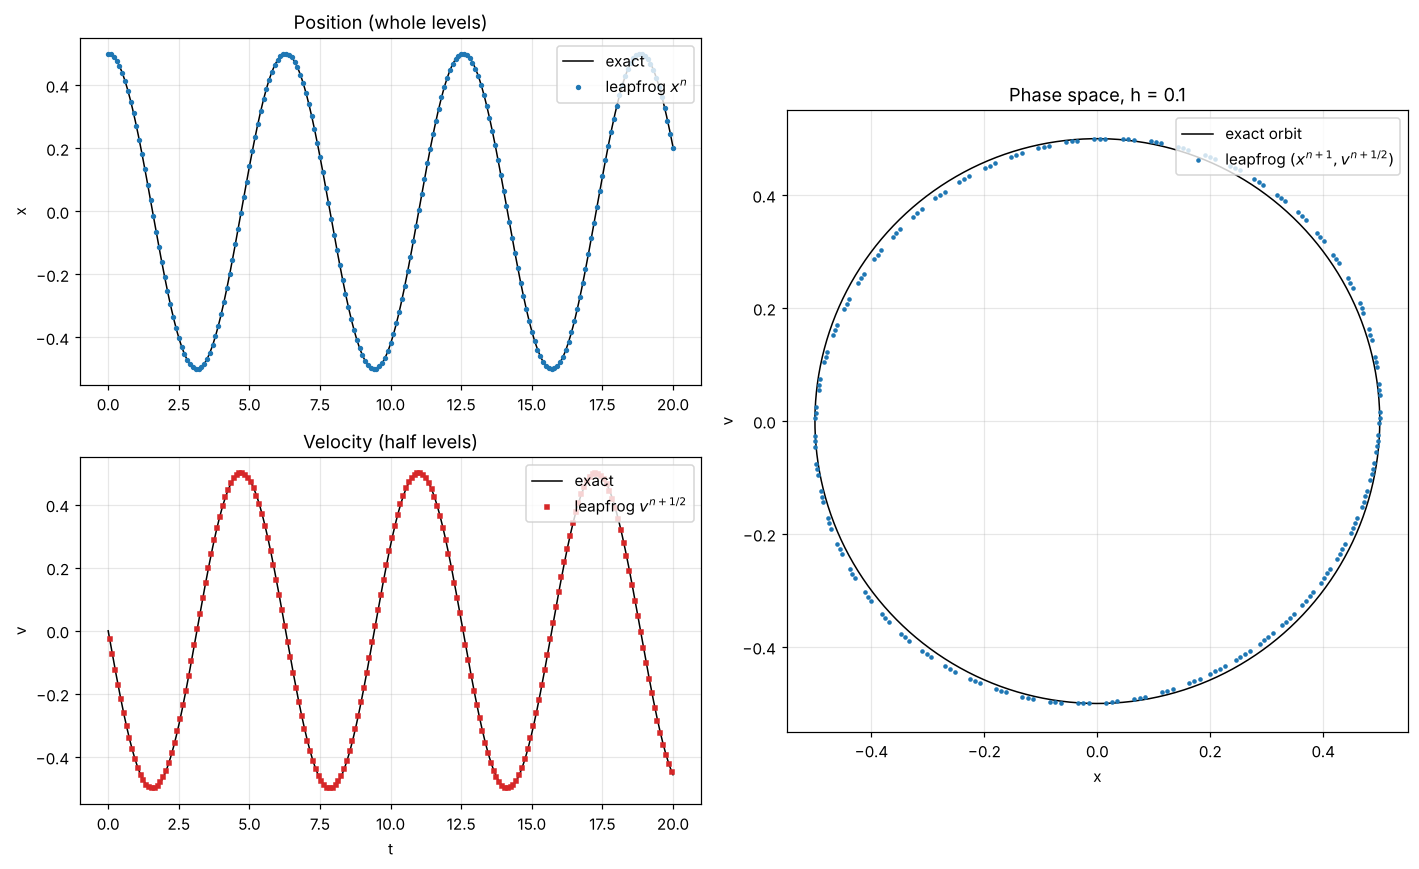

In [ ]:
tt = np.linspace(0, T_END, 2000)
fig = plt.figure(figsize=(13, 8))
ax1 = fig.add_subplot(2, 2, 1); ax2 = fig.add_subplot(2, 2, 3); ax3 = fig.add_subplot(1, 2, 2)

ax1.plot(tt, x_exact(tt), "k-", lw=1, label="exact")
ax1.plot(tx, x, "o", ms=2.5, color="C0", label="leapfrog $x^n$")
ax1.set(ylabel="x", title="Position (whole levels)"); ax1.legend(loc="upper right")

ax2.plot(tt, v_exact(tt), "k-", lw=1, label="exact")
ax2.plot(tv, v, "s", ms=2.5, color="C3", label="leapfrog $v^{n+1/2}$")
ax2.set(xlabel="t", ylabel="v", title="Velocity (half levels)"); ax2.legend(loc="upper right")

th = np.linspace(0, 2*np.pi, 400)
ax3.plot(0.5*np.cos(th), -0.5*np.sin(th), "k-", lw=1, label="exact orbit")
ax3.plot(x[1:], v, ".", ms=4, color="C0", label="leapfrog $(x^{n+1}, v^{n+1/2})$")
ax3.set_aspect("equal"); ax3.set(xlabel="x", ylabel="v", title="Phase space, h = 0.1")
ax3.legend(loc="upper right")
plt.tight_layout(); plt.show()

**Conserved quantity.** Because $\det\mathbf M = (1-\omega_p^2h^2) + \omega_p^2h^2 = 1$, the map preserves phase-space area (it is symplectic). It also conserves *exactly* a modified energy:

$$
\tilde E^n = \tfrac12\left(v^{n-1/2}\right)^2 + \tfrac12\omega_p^2\,x^n\left(x^n - h\,v^{n-1/2}\right) .
$$

This is the quadratic form $\mathbf u^T\mathbf S\,\mathbf u$ with $\mathbf M^T\mathbf S\,\mathbf M = \mathbf S$. Its constancy is a stronger test of the code than the plotted curves.

M^T S M - S =
 [[ 0. -0.]
 [ 0.  0.]]


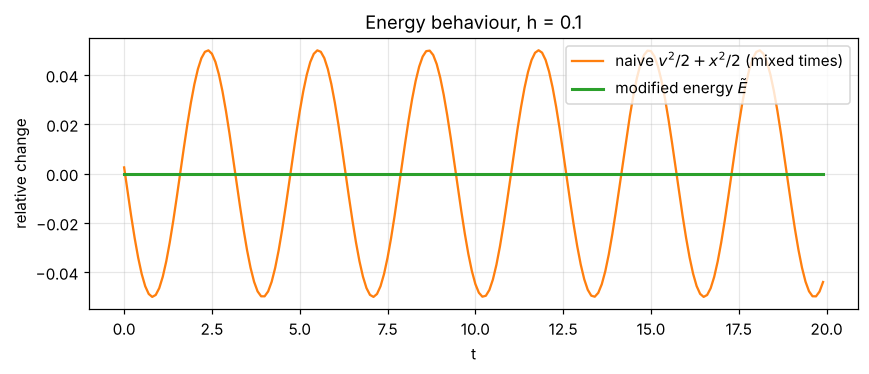

max relative change of modified energy = 1.0e-15


In [ ]:
S = lambda h: 0.5*np.array([[OMEGA_P**2, -0.5*OMEGA_P**2*h],
                            [-0.5*OMEGA_P**2*h, 1.0]])
print("M^T S M - S =\n", np.round(M_matrix(h).T @ S(h) @ M_matrix(h) - S(h), 15))

vprev = np.r_[init_half_step(X0, V0, h), v[:-1]]       # v^{n-1/2} for n = 0..N-1
E_mod = 0.5*vprev**2 + 0.5*OMEGA_P**2*x[:-1]*(x[:-1] - h*vprev)
E_naive = 0.5*vprev**2 + 0.5*OMEGA_P**2*x[:-1]**2

plt.figure(figsize=(8, 3.5))
plt.plot(tx[:-1], E_naive/0.125 - 1, color="C1", label=r"naive $v^2/2+x^2/2$ (mixed times)")
plt.plot(tx[:-1], E_mod/E_mod[0] - 1, color="C2", lw=2, label=r"modified energy $\tilde E$")
plt.xlabel("t"); plt.ylabel("relative change"); plt.legend(); plt.title("Energy behaviour, h = 0.1")
plt.tight_layout(); plt.show()
print(f"max relative change of modified energy = {np.max(np.abs(E_mod/E_mod[0]-1)):.1e}")

**Observations.**
- The class and the matrix powers agree to round-off, so the pusher implements the scheme exactly as intended.
- $x^n$ and $v^{n+1/2}$ lie on the exact curves when each is plotted at its own time level.
- The phase-space orbit is closed: no inward or outward spiral over more than three periods.
- The naive energy (which mixes $x$ and $v$ from different times) oscillates, but $\tilde E$ is constant to machine precision. This is why leapfrog has no long-term energy drift.

## Task 4 — Convergence study

For each $h \in \{0.2, 0.1, 0.05, 0.025\}$ we measure $e(h)=\max_n|x^n - x(t_n)|$ on $[0,20]$. We report the pairwise order $p_k=\log_2(e_{k}/e_{k+1})$ **and** the least-squares slope of $\log e$ against $\log h$, which uses all four points at once.

In [ ]:
hs = np.array([0.2, 0.1, 0.05, 0.025])

def errors(staggered):
    return np.array([np.max(np.abs(x_ - x_exact(t_)))
                     for t_, x_, _, _ in (solve_leapfrog(h, staggered=staggered) for h in hs)])

E_st, E_un = errors(True), errors(False)
fit_st = np.polyfit(np.log(hs), np.log(E_st), 1)
fit_un = np.polyfit(np.log(hs), np.log(E_un), 1)

print(f"{'h':>7} | {'e (staggered)':>14} {'p':>6} | {'e (v^-1/2=v0)':>14} {'p':>6}")
print("-"*58)
for k, h in enumerate(hs):
    ps = f"{np.log2(E_st[k-1]/E_st[k]):6.3f}" if k else "     —"
    pu = f"{np.log2(E_un[k-1]/E_un[k]):6.3f}" if k else "     —"
    print(f"{h:7.3f} | {E_st[k]:14.4e} {ps} | {E_un[k]:14.4e} {pu}")
print("-"*58)
print(f"least-squares order: staggered p = {fit_st[0]:.3f},  unstaggered p = {fit_un[0]:.3f}")

      h |  e (staggered)      p |  e (v^-1/2=v0)      p
----------------------------------------------------------
  0.200 |     1.5396e-02      — |     6.4557e-02      —
  0.100 |     3.8153e-03  2.013 |     2.8628e-02  1.173
  0.050 |     9.5169e-04  2.003 |     1.3402e-02  1.095
  0.025 |     2.3779e-04  2.001 |     6.4754e-03  1.049
----------------------------------------------------------
least-squares order: staggered p = 2.005,  unstaggered p = 1.105


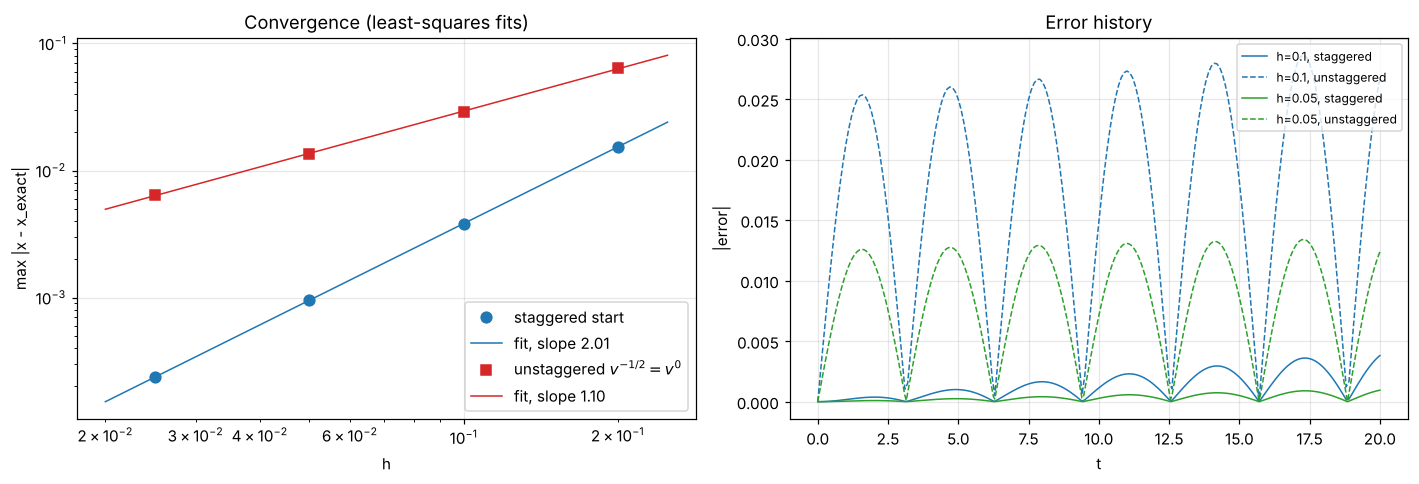

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
hh = np.geomspace(0.02, 0.25, 50)
ax[0].loglog(hs, E_st, "o", color="C0", ms=7, label="staggered start")
ax[0].loglog(hh, np.exp(np.polyval(fit_st, np.log(hh))), "-", color="C0", lw=1,
             label=f"fit, slope {fit_st[0]:.2f}")
ax[0].loglog(hs, E_un, "s", color="C3", ms=7, label="unstaggered $v^{-1/2}=v^0$")
ax[0].loglog(hh, np.exp(np.polyval(fit_un, np.log(hh))), "-", color="C3", lw=1,
             label=f"fit, slope {fit_un[0]:.2f}")
ax[0].set(xlabel="h", ylabel="max |x - x_exact|", title="Convergence (least-squares fits)")
ax[0].legend()

# Error history: shows WHERE the error comes from
for h, c in [(0.1, "C0"), (0.05, "C2")]:
    for stag, ls in [(True, "-"), (False, "--")]:
        t_, x_, _, _ = solve_leapfrog(h, staggered=stag)
        ax[1].plot(t_, np.abs(x_ - x_exact(t_)), ls, color=c, lw=1,
                   label=f"h={h}, {'staggered' if stag else 'unstaggered'}")
ax[1].set(xlabel="t", ylabel="|error|", title="Error history"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Explaining the loss of order with the matrix form.** Write the start vector as the correct one plus a perturbation: $\mathbf u^0 = \mathbf u^0_{\rm exact} + \boldsymbol\delta$. Linearity gives

$$
\mathbf u^n = \mathbf M^n\mathbf u^0_{\rm exact} + \mathbf M^n\boldsymbol\delta .
$$

The eigenvalues of $\mathbf M$ have modulus exactly 1 (Task 6), so $\|\mathbf M^n\boldsymbol\delta\|$ **neither grows nor decays**. The initial error is carried, undamped, for the entire run as an amplitude/phase error of fixed size.

| start | $\delta_v = v^{-1/2} - v(-h/2)$ | effect on $x^n$ |
|---|---|---|
| staggered | $O(h^2)$ (here $O(h^3)$) | below the scheme's own $O(h^2)$ error: **order 2 kept** |
| $v^{-1/2}=v^0$ | $\approx -0.25h = O(h)$ | dominates the $O(h^2)$ error: **order drops to 1** |

The error-history plot shows this directly. With the unstaggered start the error appears as a persistent oscillation of almost constant amplitude, which halves when $h$ halves. With the staggered start the error grows slowly (phase error) and is about 4× smaller each time $h$ halves.

The fit gives $p\approx 2.0$ for the staggered start and $p\approx 1.1$ for the unstaggered start. The pairwise values for the unstaggered start approach 1 as $h\to 0$, because the leftover $O(h^2)$ part becomes negligible.

In [ ]:
# Propagate ONLY the start perturbation delta through M^n: it reproduces the extra error
for h in [0.1, 0.05]:
    N = int(round(T_END/h))
    delta = np.array([0.0, V0 - init_half_step(X0, V0, h)])
    d = np.array([np.linalg.matrix_power(M_matrix(h), n) @ delta for n in range(N + 1)])
    t_s, x_s, _, _ = solve_leapfrog(h, staggered=True)
    t_u, x_u, _, _ = solve_leapfrog(h, staggered=False)
    print(f"h={h}:  max|x_unstag - x_stag| = {np.max(np.abs(x_u - x_s)):.4e}"
          f"   max|(M^n delta)_x| = {np.max(np.abs(d[:, 0])):.4e}")

h=0.1:  max|x_unstag - x_stag| = 2.5030e-02   max|(M^n delta)_x| = 2.5030e-02
h=0.05:  max|x_unstag - x_stag| = 1.2504e-02   max|(M^n delta)_x| = 1.2504e-02


## Task 5 — Equivalence to the central-difference formula, via Cayley–Hamilton

Every $2\times2$ matrix satisfies its own characteristic polynomial:

$$
\mathbf M^2 - (\operatorname{tr}\mathbf M)\,\mathbf M + (\det\mathbf M)\,\mathbf I = 0,
\qquad \operatorname{tr}\mathbf M = 2-\omega_p^2h^2,\quad \det\mathbf M = 1 .
$$

Multiply on the right by $\mathbf u^{n-1}$ and use $\mathbf u^{k}=\mathbf M^k\mathbf u^0$:

$$
\mathbf u^{n+1} - (2-\omega_p^2h^2)\,\mathbf u^{n} + \mathbf u^{n-1} = 0 .
$$

The first component of this vector equation is

$$
\boxed{\,x^{n+1} - 2x^n + x^{n-1} = -\omega_p^2h^2\,x^n\,}
$$

which is the central-difference approximation of $\ddot x=-\omega_p^2x$. (The velocities $v^{n+1/2}$ obey the same recurrence.)

**Order of accuracy.** Insert the exact solution into the scheme to get the local truncation error

$$
\tau(h) = \frac{x(t+h)-2x(t)+x(t-h)}{h^2} + \omega_p^2x(t).
$$

SymPy expands this below. The leading term is $\frac{h^2}{12}x^{(4)}$, so the method is **second order**, in agreement with Task 4.

In [ ]:
Ms = sp.Matrix([[1 - w**2*hs_**2, hs_], [-w**2*hs_, 1]])
print("trace M =", sp.simplify(Ms.trace()), "   det M =", sp.simplify(Ms.det()))
print("Cayley-Hamilton  M^2 - tr(M) M + det(M) I =",
      sp.simplify(Ms**2 - Ms.trace()*Ms + Ms.det()*sp.eye(2)).tolist())

# Generic Taylor expansion: d[k] = k-th derivative of x at t
d = sp.symbols("x0:8")
taylor = lambda s: sum(d[k]*s**k/sp.factorial(k) for k in range(8))
tau = sp.expand((taylor(hs_) - 2*d[0] + taylor(-hs_))/hs_**2 - d[2])
print("\n[x(t+h) - 2x(t) + x(t-h)]/h^2 - x''(t) =", tau,
      "\n   (x4, x6 denote the 4th and 6th derivatives of x at t)")

trace M = -h**2*omega_p**2 + 2    det M = 1
Cayley-Hamilton  M^2 - tr(M) M + det(M) I = [[0, 0], [0, 0]]

[x(t+h) - 2x(t) + x(t-h)]/h^2 - x''(t) = h**4*x6/360 + h**2*x4/12 
   (x4, x6 denote the 4th and 6th derivatives of x at t)


In [ ]:
# Numerical check on the h = 0.1 run
h = 0.1
tx, x, _, _ = solve_leapfrog(h)
res = x[2:] - 2*x[1:-1] + x[:-2] + (OMEGA_P*h)**2*x[1:-1]
print(f"max residual of central-difference recurrence = {np.max(np.abs(res)):.1e}")

# Truncation error of the exact solution scales like h^2 (ratio -> 4)
taus = []
for hh_ in [0.2, 0.1, 0.05, 0.025]:
    tg = np.linspace(1, 19, 500)
    taus.append(np.max(np.abs((x_exact(tg+hh_) - 2*x_exact(tg) + x_exact(tg-hh_))/hh_**2
                              + OMEGA_P**2*x_exact(tg))))
print("max |tau|:", ", ".join(f"{t:.3e}" for t in taus))
print("ratios   :", ", ".join(f"{a/b:.3f}" for a, b in zip(taus[:-1], taus[1:])), " (-> 4 => O(h^2))")

max residual of central-difference recurrence = 7.4e-17
max |tau|: 1.664e-03, 4.165e-04, 1.042e-04, 2.604e-05
ratios   : 3.996, 3.999, 4.000  (-> 4 => O(h^2))


## Task 6 — Stability from the eigenvalues of $\mathbf M$

Stability means $\mathbf M^n$ stays bounded, which requires every eigenvalue $\lambda$ of $\mathbf M$ to satisfy $|\lambda|\le1$ (and $|\lambda| = 1$ only for distinct eigenvalues). The eigenvalues solve

$$
\lambda^2 - (2-\omega_p^2h^2)\lambda + 1 = 0,\qquad \lambda_1\lambda_2=\det\mathbf M=1,\qquad \lambda_1+\lambda_2=2-\omega_p^2h^2 .
$$

Because the product is 1, either both eigenvalues lie on the unit circle or one lies outside it. There is no damped case.

- **$0<\omega_p h<2$:** $|2-\omega_p^2h^2|<2$, so the discriminant is negative and $\lambda_{1,2}=e^{\pm i\theta}$, with $\cos\theta=1-\frac12\omega_p^2h^2$. The eigenvalues are distinct and on the unit circle: **neutrally stable**.
- **$\omega_p h=2$:** $\lambda_1=\lambda_2=-1$ and $\mathbf M$ is a single Jordan block, so $\|\mathbf M^n\|\sim n$: linear growth.
- **$\omega_p h>2$:** real eigenvalues with $\lambda_1\lambda_2 = 1$ and $\lambda_1+\lambda_2<-2$, so $|\lambda_{\max}| > 1$: **exponential growth**, with sign flips every step.

$$
\boxed{\text{Stable} \iff \omega_p h < 2}
$$

The spectral radius $\rho(\mathbf M)$, computed numerically over a range of $\omega_p h$, makes the threshold visible:

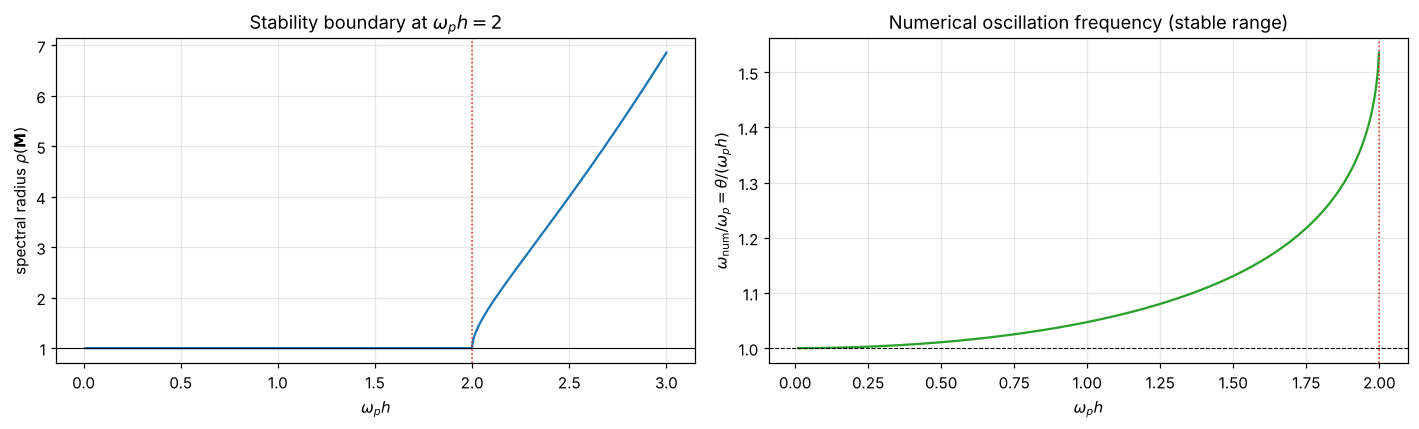

In [ ]:
wh_grid = np.linspace(0.01, 3.0, 1500)
rho = np.array([np.max(np.abs(np.linalg.eigvals(M_matrix(wh)))) for wh in wh_grid])  # omega_p = 1
theta = np.where(wh_grid < 2, np.arccos(np.clip(1 - wh_grid**2/2, -1, 1)), np.nan)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(wh_grid, rho, color="C0")
ax[0].axvline(2, color="C3", ls=":", lw=1); ax[0].axhline(1, color="k", lw=0.7)
ax[0].set(xlabel=r"$\omega_p h$", ylabel=r"spectral radius $\rho(\mathbf{M})$",
          title="Stability boundary at $\\omega_p h = 2$")
ax[1].plot(wh_grid, theta/wh_grid, color="C2")
ax[1].axhline(1, color="k", ls="--", lw=0.7); ax[1].axvline(2, color="C3", ls=":", lw=1)
ax[1].set(xlabel=r"$\omega_p h$", ylabel=r"$\omega_{\rm num}/\omega_p=\theta/(\omega_p h)$",
          title="Numerical oscillation frequency (stable range)")
plt.tight_layout(); plt.show()

### Numerical runs at $\omega_p h = 1.9,\ 1.99,\ 2.01,\ 2.1$

Each case is run for 60 steps, since $t\le 20$ contains only about 10 steps at $h\approx2$. The measured growth factor per step, $|x^{n}|^{1/n}$ fitted over the run, is compared with the predicted $\rho(\mathbf M)$.

In [ ]:
cases, nst = [1.9, 1.99, 2.01, 2.1], 60
runs = {}
print(f"{'w_p h':>6} | {'eigenvalues of M':^36} | {'rho(M)':>7} | {'measured':>8} | {'|x_60|':>9}")
print("-"*80)
for wh in cases:
    t_, x_, _, _ = solve_leapfrog(wh/OMEGA_P, nsteps=nst)
    runs[wh] = x_
    lam = np.linalg.eigvals(M_matrix(wh/OMEGA_P))
    n = np.arange(nst + 1)
    meas = np.exp(np.polyfit(n[10:], np.log(np.abs(x_[10:]) + 1e-300), 1)[0])  # growth per step
    ls = ", ".join(f"{z.real:+.4f}{z.imag:+.4f}j" for z in lam)
    print(f"{wh:6.2f} | {ls:^36} | {np.max(np.abs(lam)):7.4f} | {meas:8.4f} | {abs(x_[-1]):9.2e}")

 w_p h |           eigenvalues of M           |  rho(M) | measured |    |x_60|
--------------------------------------------------------------------------------
  1.90 |   -0.8050+0.5933j, -0.8050-0.5933j   |  1.0000 |   0.9923 |  4.59e-01
  1.99 |   -0.9801+0.1988j, -0.9801-0.1988j   |  1.0000 |   0.9890 |  4.23e-01
  2.01 |   -1.2213+0.0000j, -0.8188+0.0000j   |  1.2213 |   1.2212 |  4.05e+04
  2.10 |   -1.8773+0.0000j, -0.5327+0.0000j   |  1.8773 |   1.8773 |  6.46e+15


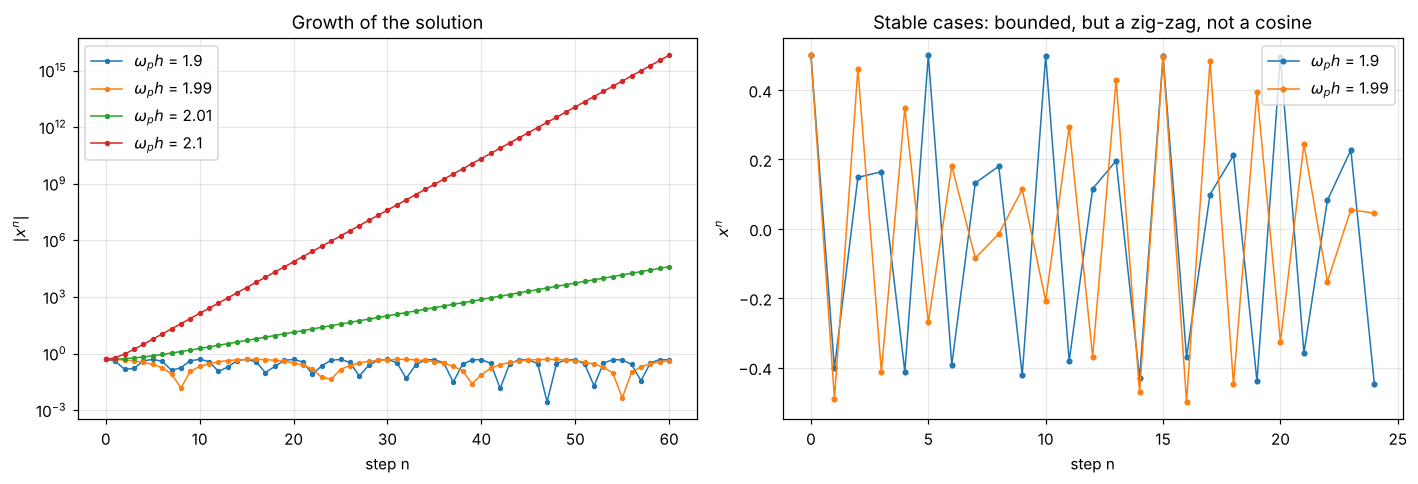

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
n = np.arange(nst + 1)
for i, wh in enumerate(cases):
    ax[0].semilogy(n, np.abs(runs[wh]) + 1e-16, "o-", ms=2.5, lw=1, color=f"C{i}",
                   label=f"$\\omega_p h$ = {wh}")
ax[0].set(xlabel="step n", ylabel=r"$|x^n|$", title="Growth of the solution"); ax[0].legend()

for i, wh in enumerate(cases[:2]):
    ax[1].plot(n[:25], runs[wh][:25], "o-", ms=3, lw=1, color=f"C{i}", label=f"$\\omega_p h$ = {wh}")
ax[1].set(xlabel="step n", ylabel=r"$x^n$", title="Stable cases: bounded, but a zig-zag, not a cosine")
ax[1].legend(); plt.tight_layout(); plt.show()

**Discussion of the runs.**
- $\omega_p h=1.9,\ 1.99$: $\rho(\mathbf M)=1$ and the solution stays bounded, but $\theta$ is close to $\pi$, so the result is a near period-2 zig-zag. The numerical frequency is about 32% too high at $\omega_p h=1.9$ and tends to $\pi/2$ times the true value as $\omega_p h\to2$. Stable does not mean accurate.
- $\omega_p h=2.01$: $\rho\approx1.22$; $\omega_p h=2.1$: $\rho\approx1.88$. The growth factors measured from the runs match $\rho(\mathbf M)$, confirming the eigenvalue analysis.

### Why every explicit PIC code must respect $\omega_p\Delta t<2$

Any local displacement of electrons relative to the ions sets up a charge-separation field that pulls them back. For small displacements this is exactly $\ddot x = -\omega_p^2 x$ with $\omega_p^2 = n_e e^2/(\varepsilon_0 m_e)$. This collective response exists in every PIC simulation, whatever the grid, geometry or particle shape. So when an explicit leapfrog pusher advances the particles, the plasma-oscillation mode is advanced by exactly the matrix $\mathbf M$ analysed above.

If $\omega_p\Delta t>2$ anywhere (the limit is set by the **densest** region, since $\omega_p\propto\sqrt{n_e}$), that mode has $|\lambda|>1$. The particle noise that is always present is amplified every step, field energy grows exponentially, and the run blows up. Codes therefore choose $\omega_p\Delta t\approx0.1$–$0.2$. That keeps them far from the stability edge and also keeps the frequency error ($\omega_{\rm num}/\omega_p - 1 \approx \omega_p^2\Delta t^2/24$) below about 0.2%.

In [ ]:
for wh in [0.1, 0.2, 0.5, 1.0, 1.9]:
    print(f"w_p h = {wh:4.1f}:  omega_num/omega_p - 1 = {np.arccos(1-wh**2/2)/wh - 1:.2e}"
          f"   (estimate (w_p h)^2/24 = {wh**2/24:.2e})")

w_p h =  0.1:  omega_num/omega_p - 1 = 4.17e-04   (estimate (w_p h)^2/24 = 4.17e-04)
w_p h =  0.2:  omega_num/omega_p - 1 = 1.67e-03   (estimate (w_p h)^2/24 = 1.67e-03)
w_p h =  0.5:  omega_num/omega_p - 1 = 1.07e-02   (estimate (w_p h)^2/24 = 1.04e-02)
w_p h =  1.0:  omega_num/omega_p - 1 = 4.72e-02   (estimate (w_p h)^2/24 = 4.17e-02)
w_p h =  1.9:  omega_num/omega_p - 1 = 3.19e-01   (estimate (w_p h)^2/24 = 1.50e-01)


## Summary

| Task | Method used here | Result |
|---|---|---|
| 1 | Class-based, in-place vectorized pusher with a general force function | $10^5$ particles pushed together, all following $x_0\cos t$ |
| 2 | Taylor expansion, checked symbolically | $v^{-1/2}=v^0-\tfrac h2a(x^0)$, error $O(h^2)$ (here $O(h^3)$) |
| 3 | Check against the exact solution, matrix powers $\mathbf M^n\mathbf u^0$, and the exactly conserved modified energy | Agreement to round-off; closed phase-space orbit |
| 4 | Least-squares slope plus pairwise orders; propagation of the start error by $\mathbf M^n$ | $p\approx2$ (staggered) vs $p\approx1$ (unstaggered) |
| 5 | Cayley–Hamilton on $\mathbf M$; SymPy truncation-error expansion | $x^{n+1}-2x^n+x^{n-1}=-\omega_p^2h^2x^n$, $\tau=\tfrac{h^2}{12}x^{(4)}$ |
| 6 | Eigenvalues / spectral radius of $\mathbf M$ | Stable iff $\omega_p h<2$; measured growth equals $\rho(\mathbf M)$ |